## Load Packages, Silently

In [1]:
## Create a vector of the required packages for this analysis
req_packages <- c("ape", "clusterProfiler", "cowplot", "ggplot2", "ggtree", "ggpubr",
                  "gridExtra", "janitor", "patchwork", "RColorBrewer", "scater",
                  "Seurat", "stringr", "tidyverse", "vegan", "viridis")

## load the packages, quietly
invisible(suppressWarnings(suppressMessages(
    lapply(req_packages, require, character.only = TRUE)
)))

## Set up data, for all figures

In [2]:
## load in parasperm content information and the obscura tree
parasperm <- read_csv("../workflow/tools/parasperm_proportion.csv", skip = 1) %>%
    janitor::clean_names() %>%
    mutate(species = str_replace(species, "D. ", "Drosophila_")) %>%
    rename(parasperm = 2) %>%
    select(species, parasperm)
tree <- ape::read.tree("../workflow/tools/select_obscura_tree.nwk")
change_df <- read_tsv("../workflow/tools/CAGEE/cagee_midlow/clade_results.tab") %>%
    janitor::clean_names()


New names:
• `` -> `...5`
Rows: 10 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): species, Category, Remating in days (from Holman et al 2007 Evoluti...
dbl (1): % Parasperm

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 14 Columns: 3
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (1): #Taxon_ID
dbl (2): Increase, Decrease

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
## load in vep results
raw_variants <- read_tsv("../workflow/tools/VEP/variant_effect_output.txt", skip = 95) %>%
    janitor::clean_names()

## clean up the column information
all_variants <- raw_variants %>%
    separate_wider_delim(extra, ";", names = c("impact", "distance", "strand", "class", "symbol", "biotype"), 
                         too_few = "align_start", too_many = "drop") %>%
    mutate(biotype = case_when(grepl("BIOTYPE", symbol) ~ symbol,
                               TRUE ~ biotype),
           symbol = case_when(grepl("SYMBOL", class) ~ class,
                              TRUE ~ symbol),
           class = case_when(grepl("VARIANT_CLASS", distance) ~ distance,
                             grepl("VARIANT_CLASS", strand) ~ strand,
                             TRUE ~ class),
           strand = case_when(grepl("STRAND", distance) ~ distance,
                              TRUE ~ strand),
           distance = case_when(!grepl("DISTANCE", distance) ~ NA,
                                TRUE ~ distance)) %>%
    mutate(across(everything(), ~ str_replace(., ".*=", ""))) %>%
    separate_wider_delim(number_uploaded_variation, "_", names = c("chromosome", "position", "change"), too_few = "align_start", too_many = "drop") %>%
    mutate(position = as.integer(position))

## filter for only variants on the XR
variants <- all_variants %>%
    filter(grepl("ChrX", chromosome)) %>%
    filter(grepl("ChrX.1", chromosome) | grepl("ChrX.4", chromosome))

Warning message:
“One or more parsing issues, call `problems()` on your data frame for details,
e.g.:
  dat <- vroom(...)
  problems(dat)”
Rows: 5891958 Columns: 14
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (14): #Uploaded_variation, Location, Allele, Gene, Feature, Feature_type...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [4]:
## load RNA reads from across the obscura group
reads <- read_tsv("../workflow/tools/obscura_group_reads.tsv") %>%
    janitor::clean_names()

## load in gene location information
gene_loc <- read_csv("intermediate/gene_chromosome.csv")

## pull genes on the X chromosome
x_genes <- gene_loc %>%
    filter(chromosome == "X") %>%
    pull("gene_id") %>%
    unique()

## load in branch information
credible_df <- read_csv("../workflow/tools/CAGEE/credible_genes.csv") %>%
    mutate(across(everything(), ~ str_replace(., "\\*", "")),
           mutate(across(starts_with("x"), ~ as.numeric(.x))),
           sign = case_when(signif == 14 ~ x_14,
                            signif == 15 ~ x_15,
                            signif == 12 ~ x_12)) %>%
    na.omit()

## get list of credible genes
credible_genes <- unique(credible_df$transcript_id)
credible_down_genes <- credible_df %>%
    filter(sign < 0) %>%
    pull("transcript_id")
credible_up_genes <- credible_genes[!(credible_genes %in% credible_down_genes)]

Rows: 16880 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (2): DESC, Gene_ID
dbl (8): Drosophila_affinis, Drosophila_azteca, Drosophila_bifasciata, Droso...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 16880 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (5): gene_id, diff, dir, chromosome, x_chr

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 563 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): transcript_id, x_12, x_14, x_15
num (1): signif

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = F

In [5]:
## load in tau data
tau <- read.csv("../workflow/yang2018_rnaseq/results/tau_tissue_0.50.csv")
testes_genes <- tau %>%
    filter(tau_tissue == "male_gonad") %>%
    pull("gene")

In [6]:
## load in LogFC data
logfc <- read_csv("../workflow/multigenome_rnaseq/results/logfc_normalized.csv")

New names:
• `` -> `...1`
Rows: 28593 Columns: 8
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (5): gene, comparison, significance, direction, color
dbl (3): ...1, logfc, pvalue

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [7]:
## load in GO term assignment for differentially expressed genes in the mutant
pseudoobscura_mutant_go <- read_csv("intermediate/pseudoobscura_mutant_go.csv")

New names:
• `` -> `...1`
Rows: 24315 Columns: 7
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): go_term, direction
dbl (5): ...1, go_genes, go_ratio, go_pvalue, pvalue_corrected

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [8]:
## load in GO term information for EvoGeneX and CAGEE
credible_go <- read_csv("intermediate/credible_go.csv")

New names:
• `` -> `...1`
Rows: 2838 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): go_term
dbl (5): ...1, go_genes, go_ratio, go_pvalue, pvalue_corrected

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [9]:
## load in GO terms for branch associated genes that are upregulated in the mutant
downcred_go <- read_csv("intermediate/credible_down_go.csv")

New names:
• `` -> `...1`
Rows: 1543 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): go_term
dbl (5): ...1, go_genes, go_ratio, go_pvalue, pvalue_corrected

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [10]:
## load in results
sce_markers <- read_csv("../workflow/he2026_scrnaseq/results/pseudoobscura_testis_markers.csv")
markers_go <- read_csv("../workflow/he2026_scrnaseq/results/spermatogenesis_markers_go.csv")

Rows: 24858 Columns: 7
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): cluster, gene
dbl (5): p_val, avg_log2FC, pct.1, pct.2, p_val_adj

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 80178 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): go_term, cluster
dbl (4): go_genes, go_ratio, go_pvalue, pvalue_corrected

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [11]:
## load in single cell results
sce <- readRDS("../workflow/he2026_scrnaseq/results/processed_sce.rds")

## get the orthology data frame
dmel_dpse <- read_delim("../workflow/trinotate/drosoma_pse_mel.txt", col_names = FALSE)
names(dmel_dpse) <- c("dpse", "dmel", "paralog", "score")

Rows: 13772 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (3): X1, X2, X3
dbl (1): X4

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [12]:
## load processed single cell experiment object
sce <- readRDS("intermediate/processed_sce.rds")

## load in logFC between stages data
logfc_morph <- read_csv("intermediate/logfc_morph_stage.csv")

## Create Figures

### Figure 1

Warning message:
“`aes_()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`
ℹ The deprecated feature was likely used in the ggtree package.
  Please report the issue at <https://github.com/YuLab-SMU/ggtree/issues>.”
Warning message in fortify(data, ...):
“Arguments in `...` must be used.
✖ Problematic arguments:
• as.Date = as.Date
• yscale_mapping = yscale_mapping
• hang = hang
ℹ Did you misspell an argument name?”


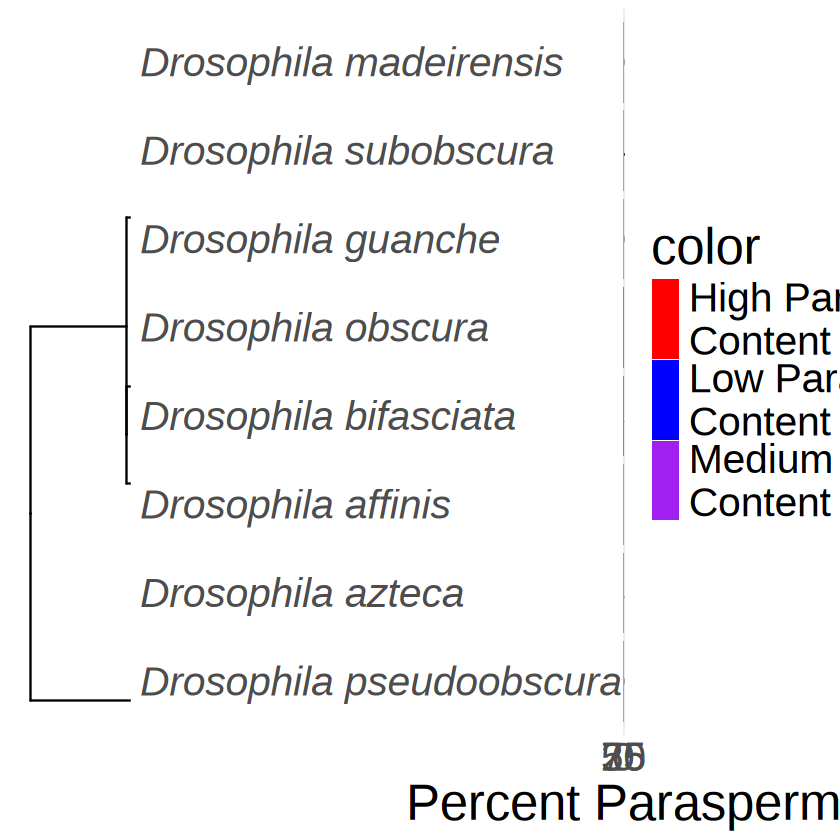

In [ ]:
## get the percent parasperm measured
parasperm_percent <- parasperm %>%
    rename(label = species)

## annotate tree with percent parasperm
tree_label <- tree %>%
    as_tibble() %>%
    mutate(label = str_replace_all(label, " ", "_")) %>%
    full_join(parasperm_percent, by = "label") %>%
    mutate(label = str_replace_all(label, "_", " "))

figure1a <- ggtree(tree) %<+% 
    tree_label +
    xlim(NA, 20) +
    labs(title = "")

figure1b <- tree_label %>%
    filter(grepl("Drosophila", label)) %>%
    mutate(color = case_when(parasperm > 65 ~ "High Parasperm\nContent",
                             parasperm < 40 ~ "Low Parasperm\nContent",
                             TRUE ~ "Medium Parasperm\nContent")) %>%
    ggplot(aes(x = factor(label, levels = c("Drosophila pseudoobscura", "Drosophila azteca", "Drosophila affinis", "Drosophila bifasciata",
                                                                   "Drosophila obscura", "Drosophila guanche", "Drosophila subobscura", "Drosophila madeirensis")))) +
        geom_bar(aes(y = parasperm, fill = color), stat = "identity") +
        geom_text(aes(y = parasperm + 3, label = parasperm), size = 6) +
        labs(y = "Percent Parasperm") +
        scale_fill_manual(values = c("red", "blue", "purple")) +
        theme_minimal() +
        theme(text = element_text(size = 30),
              axis.title.y = element_blank(),
              axis.text.y = element_text(face = "italic", hjust = 0)) +
        coord_flip()

figure1 <- plot_grid(figure1a, NULL, figure1b, rel_widths = c(1, -0.3, 1), nrow = 1)
figure1

In [ ]:
ggsave("figures/figure1a.png", figure1a, width = 10, height = 9)
ggsave("figures/figure1b.png", figure1b, width = 15, height = 10)

### Figure 2

Warning message in fortify(data, ...):
“Arguments in `...` must be used.
✖ Problematic arguments:
• as.Date = as.Date
• yscale_mapping = yscale_mapping
• hang = hang
ℹ Did you misspell an argument name?”
Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ggtree package.
  Please report the issue at <https://github.com/YuLab-SMU/ggtree/issues>.”
Warning message:
“The `label.size` argument of `geom_label()` is deprecated as of ggplot2 3.5.0.
ℹ Please use the `linewidth` argument instead.”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_label()`).”


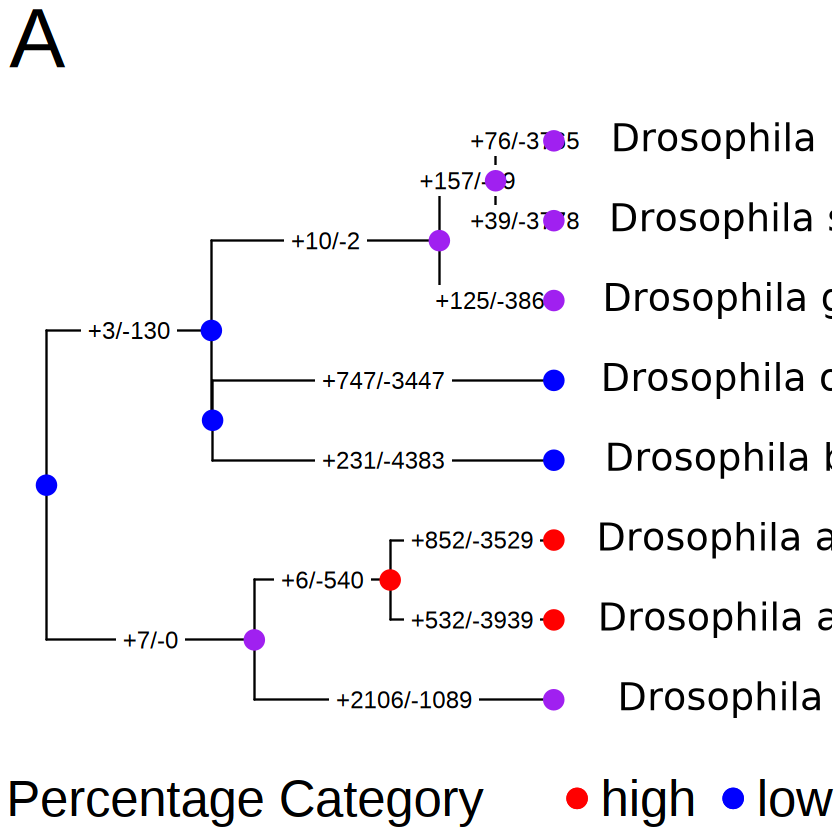

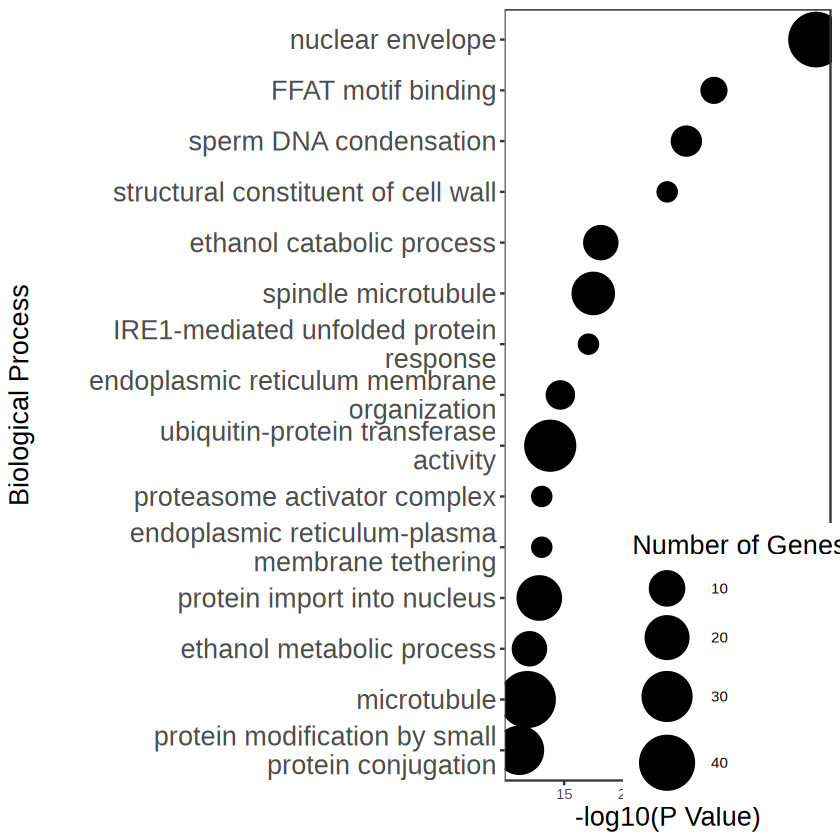

In [ ]:
## get number of credible changes at each branch
branch_change <- change_df %>%
    separate_wider_delim(number_taxon_id, "<", names = c("name", "node")) %>%
    select(-name) %>%
    mutate(node = str_replace(node, ">", ""),
           node = as.numeric(node),
           change = paste0("+", increase, "/-", decrease)) %>%
    select(c("node", "change"))

## compile metadata into tibble
tree_label <- tree %>%
    as_tibble() %>%
    left_join(branch_change, by = "node") %>%
    mutate(label = str_replace_all(label, "_", " ")) %>%
    add_column(color = c("low", "low", "medium", "medium", "medium", "high", "high", "medium",
                            "low", "low", "low", "medium", "medium", "medium", "high"))
tree_label[11, "change"] <- NA
tree$tip.label <- gsub("_", " ", tree$tip.label)

## plot tree
figure2a <- ggtree(tree) %<+% 
    tree_label +
    geom_tiplab(geom = "text", aes(label = paste0("italic(\'", label, "\')")), parse = TRUE,
                hjust = -0.12, size = 8) +
    geom_label(aes(x = branch, label = change), label.size = 0, size = 5) +
    geom_nodepoint(aes(color = color), size = 5) +
    geom_tippoint(aes(color = color), size = 5) +
    xlim(NA, 20) +
    labs(title = "A", color = "Parasperm Percentage Category") +
    scale_color_manual(values = c("red", "blue", "purple")) +
    theme(plot.title = element_text(size = 50),
          legend.position = "bottom",
          legend.title = element_text(size = 30),
          legend.text = element_text(size = 30))

## get list of terms that do not exist in Drosophila, as artifacts of Trinotate
artifacts <- c("T cells", "interferon")
artifacts <- paste(artifacts, collapse = "|")

## plot the enriched GO terms for the parasperm associated genes
figure2b <- credible_go %>%
    filter(pvalue_corrected < 0.05 & !grepl(artifacts, go_term)) %>%
    arrange(pvalue_corrected) %>%
    slice(1:15) %>%
    mutate(go_term = str_wrap(go_term, width = 35)) %>%
    ggplot(aes(x = fct_reorder(go_term, -log10(pvalue_corrected)), y = -log10(pvalue_corrected), size = go_genes)) +
        geom_point() +
        labs(x = "Biological Process", y = "-log10(P Value)", size = "Number of Genes") +
        # scale_color_gradient(low = "#C5E0B4", high = "#385723") +
        scale_size(range = c(5, 15)) +
        theme_bw() +
        theme(panel.grid = element_blank(),
              legend.position = c(0.75, 0.15),
              legend.title = element_text(size = 16),
              plot.title = element_text(size = 20),
              axis.text.y = element_text(size = 16),
              axis.title = element_text(size = 16)) +
        coord_flip()

figure2a
figure2b

In [ ]:
ggsave("figures/figure2a.png", figure2a, width = 18, height = 10)
ggsave("figures/figure2b.png", figure2b, height = 9, width = 9)

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_label()`).”


### Figure 3

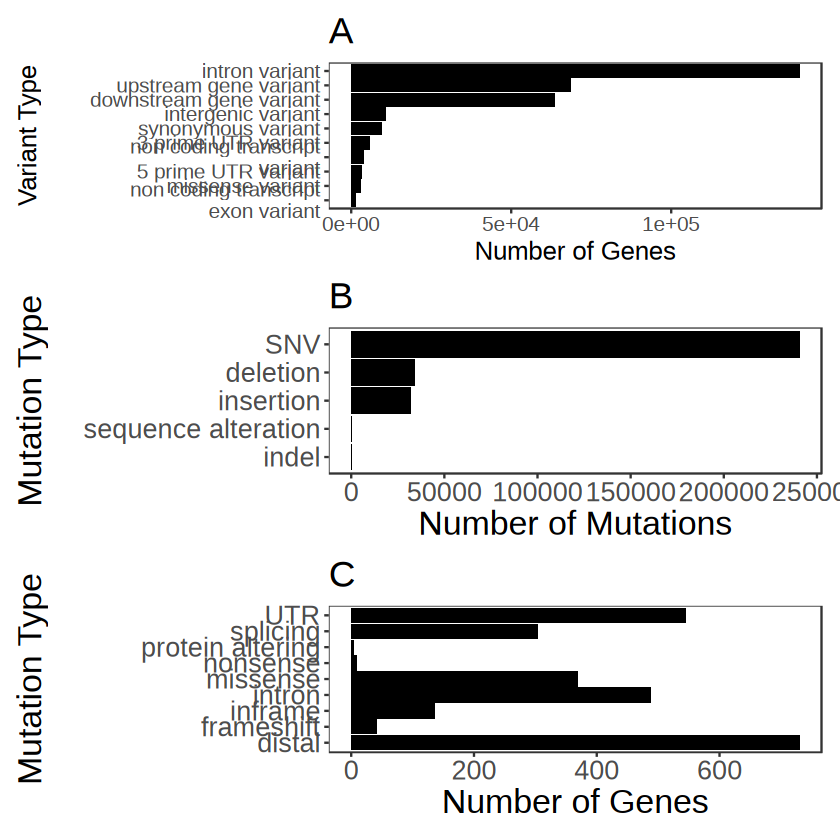

In [ ]:
## annotate mutation types
variant_type <- variants %>%
    separate_longer_delim(consequence, delim = ",") %>%
    mutate(type = case_when(grepl("UTR", consequence) ~ "UTR",
                            grepl("splice", consequence) ~ "splicing",
                            grepl("intron", consequence) ~ "intron",
                            grepl("frameshift", consequence) ~ "frameshift",
                            grepl("inframe", consequence) ~ "inframe",
                            grepl("start_lost", consequence) | grepl("stop_gained", consequence) ~ "nonsense",
                            grepl("missense", consequence) ~ "missense",
                            grepl("protein_altering", consequence) ~ "protein altering",
                            grepl("stream_gene_variant", consequence) ~ "distal"))
                        
## create graphs to look at classifications of data
variant_type_graph <- variants %>%
    separate_longer_delim(consequence, delim = ",") %>%
    group_by(consequence) %>%
    summarize(count = n()) %>%
    arrange(desc(count)) %>%
    head(10) %>%
    mutate(consequence = str_replace_all(consequence, "_", " "),
           consequence = str_wrap(consequence, width = 25)) %>%
    ggplot(aes(x = reorder(consequence, count), y = count)) +
        geom_bar(stat = "identity", fill = "black") +
        labs(x = "Variant Type", y = "Number of Genes") +
        theme_bw() +
        theme(panel.grid = element_blank()) +
    coord_flip()
mutation_type_graph <- variants %>%
    group_by(class) %>%
    summarize(count = n()) %>%
    mutate(class = str_replace_all(class, "_", " ")) %>%
    ggplot(aes(x = reorder(class, count), y = count)) +
        geom_bar(stat = "identity", fill = "black") +
        labs(x = "Mutation Type", y = "Number of Mutations") +
        theme_bw()+
        theme(panel.grid = element_blank()) +
    coord_flip()
variant_number_graph <- variant_type %>%
    select(type, symbol) %>%
    na.omit() %>%
    unique() %>%
    count(type) %>%
    ggplot(aes(x = type, y = n)) +
        geom_bar(stat = "identity", fill = "black") +
        labs(x = "Mutation Type", y = "Number of Genes") +
        theme_bw() +
        theme(panel.grid = element_blank()) +
    coord_flip()

## add figure annotations
figure3a <- variant_type_graph +
    labs(title = "A") +
    theme(text = element_text(size = 15),
          plot.title = element_text(size = 22))
figure3b <- mutation_type_graph +
    labs(title = "B") +
    theme(text = element_text(size = 20),
          plot.title = element_text(size = 22))

figure3c <- variant_number_graph +
    labs(title = "C") +
    theme(text = element_text(size = 20),
          plot.title = element_text(size = 22))

## plot graphs together
figure3 <- figure3a / figure3b / figure3c
figure3

In [ ]:
ggsave("figures/figure3.png", figure3, height = 10, width = 8)

### Figure 4

In [ ]:
## combine differential expression and parasperm data
annotated_logfc <- reads$gene_id %>%
    as.data.frame() %>%
    rename(gene = 1) %>%
    left_join(logfc, by = "gene") %>%
    filter(comparison == "sex ratio_mutant") %>%
    select(gene, logfc, pvalue, significance, color) %>%
    unique() %>%
    mutate(logfc = -(logfc),
           credible = case_when(gene %in% credible_down_genes ~ "credible",
                                TRUE ~ "non-credible"),
           significance = case_when(is.na(significance) ~ "not significant",
                                    TRUE ~ significance),
           color = case_when(is.na(color) ~ "not significant",
                             TRUE ~ color),
           direction = case_when(significance == "significant" & logfc < 0 ~ "hypo",
                                 significance == "significant" & logfc > 0 ~ "hyper",
                                 TRUE ~ "not significant"),
           testes_specificity = case_when(gene %in% testes_genes ~ "testes",
                                          TRUE ~ "other"),
           x = case_when(gene %in% x_genes ~ "x",
                         TRUE ~ "other"),
           both = case_when(gene %in% x_genes & gene %in% testes_genes ~ "both",
                            TRUE ~ "other")) %>%
    unique()

In [ ]:
## save number of genes and labels
gene_numbers <- annotated_logfc %>%
    count(direction) %>%
    t() %>%
    as.data.frame() %>%
    row_to_names(1) %>%
    as.list()
up_rawlabel <- paste0("Up in Mutant = ", gene_numbers["hyper"])
down_rawlabel <- paste0("Down in Mutant = ", gene_numbers["hypo"])
not_rawlabel <- paste0("Not significant = ", gene_numbers["not significant"])

## get an unannotated logfc
logfc_raw <- annotated_logfc %>%
    na.omit() %>%
    ggplot(aes(x = logfc, y = -log10(pvalue), color = direction)) +
        geom_point(size = 0.25, alpha = 0.75) +
        labs(title = "A) All Genes", x = "LogFC", y = "-log10(P Value)") +
        xlim(-15, 15) +
        ylim(0, 15) +
        scale_color_manual(values = c("steelblue2", "steelblue4", "light gray")) +
        theme_bw() +
        theme(panel.grid = element_blank(),
              legend.position = "none",
              plot.title = element_text(hjust = 0.5, size = 15))
figure4a <- logfc_raw +
    annotate("text", x = -15, y = 15, hjust = 0,
             size = 2, label = up_rawlabel) +
    annotate("text", x = -15, y = 14.5, hjust = 0,
             size = 2, label = down_rawlabel)

In [ ]:
## now look at testes, separating increase and decrease
testes_up <- annotated_logfc %>%
    filter(direction != "hypo") %>%
    group_by(testes_specificity, direction) %>%
    count() %>%
    pivot_wider(names_from = direction, values_from = n) %>%
    column_to_rownames("testes_specificity") %>%
    mutate_all(replace_na, replace = 0) %>%
    as.matrix() %>%
    chisq.test()
testes_down <- annotated_logfc %>%
    filter(direction != "hyper") %>%
    group_by(testes_specificity, direction) %>%
    count() %>%
    pivot_wider(names_from = direction, values_from = n) %>%
    column_to_rownames("testes_specificity") %>%
    mutate_all(replace_na, replace = 0) %>%
    as.matrix() %>%
    chisq.test()

## now look at x, separating increase and decrease
x_up <- annotated_logfc %>%
    filter(direction != "hypo") %>%
    group_by(x, direction) %>%
    count() %>%
    pivot_wider(names_from = direction, values_from = n) %>%
    column_to_rownames("x") %>%
    mutate_all(replace_na, replace = 0) %>%
    as.matrix() %>%
    chisq.test()
x_down <- annotated_logfc %>%
    filter(direction != "hyper") %>%
    group_by(x, direction) %>%
    count() %>%
    pivot_wider(names_from = direction, values_from = n) %>%
    column_to_rownames("x") %>%
    mutate_all(replace_na, replace = 0) %>%
    as.matrix() %>%
    chisq.test()

## now look at both x and testes, separating increase and decrease
both_up <- annotated_logfc %>%
    filter(direction != "hypo") %>%
    group_by(both, direction) %>%
    count() %>%
    pivot_wider(names_from = direction, values_from = n) %>%
    column_to_rownames("both") %>%
    mutate_all(replace_na, replace = 0) %>%
    as.matrix() %>%
    chisq.test()
both_down <- annotated_logfc %>%
    filter(direction != "hyper") %>%
    group_by(both, direction) %>%
    count() %>%
    pivot_wider(names_from = direction, values_from = n) %>%
    column_to_rownames("both") %>%
    mutate_all(replace_na, replace = 0) %>%
    as.matrix() %>%
    chisq.test()

In [ ]:
## sub sample logfc based on characteristics of genes
logfc_testes <- annotated_logfc %>%
    filter(testes_specificity == "testes") %>%
    na.omit %>%
    ggplot(aes(x = logfc, y = -log10(pvalue), color = direction)) +
        geom_point(size = 0.25, alpha = 0.75) +
        labs(title = "B) Testis Biased", x = "LogFC", y = "-log10(P Value)") +
        xlim(-15, 15) +
        ylim(0, 15) +
        scale_color_manual(values = c("steelblue2", "steelblue4", "light gray")) +
        theme_bw() +
        theme(panel.grid = element_blank(),
              legend.position = "none",
              plot.title = element_text(hjust = 0.5, size = 15))
logfc_x <- annotated_logfc %>%
    filter(x == "x") %>%
    na.omit %>%
    ggplot(aes(x = logfc, y = -log10(pvalue), color = direction)) +
        geom_point(size = 0.25, alpha = 0.75) +
        labs(title = "C) On X Chromosome", x = "LogFC", y = "-log10(P Value)") +
        xlim(-15, 15) +
        ylim(0, 15) +
        scale_color_manual(values = c("steelblue2", "steelblue4", "light gray")) +
        theme_bw() +
        theme(panel.grid = element_blank(),
              legend.position = "none",
              plot.title = element_text(hjust = 0.5, size = 15))
logfc_both <- annotated_logfc %>%
    filter(both == "both") %>%
    na.omit %>%
    ggplot(aes(x = logfc, y = -log10(pvalue), color = direction)) +
        geom_point(size = 0.25, alpha = 0.75) +
        labs(title = "D) On X, Testis Biased", x = "LogFC", y = "-log10(P Value)") +
        xlim(-15, 15) +
        ylim(0, 15) +
        scale_color_manual(values = c("steelblue2", "steelblue4", "light gray")) +
        theme_bw() +
        theme(panel.grid = element_blank(),
              legend.position = "none",
              plot.title = element_text(hjust = 0.5, size = 15))

## add graph details to testes specific
testes_numbers <- annotated_logfc %>%
    filter(testes_specificity == "testes") %>%
    count(direction) %>%
    t() %>%
    as.data.frame() %>%
    row_to_names(1) %>%
    as.list()
up_testeslabel <- paste0("Up in Mutant = ", testes_numbers["hyper"], "/", length(testes_genes))
up_testesp <- paste0("p = ", signif(testes_up$p.value, digits = 4))
down_testeslabel <- paste0("Down in Mutant = ", testes_numbers["hypo"], "/", length(testes_genes))
down_testesp <- paste0("p = ", signif(testes_down$p.value, digits = 4))

figure4b <- logfc_testes +
    annotate("text", x = -15, y = 15, hjust = 0,
             size = 2, label = up_testeslabel) +
    annotate("text", x = -14, y = 14.5, hjust = 0,
             size = 2, label = "p < 1.00 e-25") +
    annotate("text", x = -15, y = 13, hjust = 0,
             size = 2, label = down_testeslabel) +
    annotate("text", x = -14, y = 12.5, hjust = 0,
             size = 2, label = "p < 1.00 e-25")

## add graph details to x
x_numbers <- annotated_logfc %>%
    filter(x == "x") %>%
    count(direction) %>%
    t() %>%
    as.data.frame() %>%
    row_to_names(1) %>%
    as.list()
up_xlabel <- paste0("Up in Mutant = ", x_numbers["hyper"], "/", length(x_genes))
up_xp <- paste0("p = ", signif(x_up$p.value, digits = 4))
down_xlabel <- paste0("Down in Mutant = ", x_numbers["hypo"], "/", length(x_genes))
down_xp <- paste0("p = ", signif(x_down$p.value, digits = 4))

figure4c <- logfc_x +
    annotate("text", x = -15, y = 15, hjust = 0,
             size = 2, label = up_xlabel) +
    annotate("text", x = -14, y = 14.5, hjust = 0,
             size = 2, label = up_xp) +
    annotate("text", x = -15, y = 13, hjust = 0,
             size = 2, label = down_xlabel) +
    annotate("text", x = -14, y = 12.5, hjust = 0,
             size = 2, label = down_xp)

## add graph details to both
both_genes <- x_genes[x_genes %in% testes_genes]
both_numbers <- annotated_logfc %>%
    filter(both == "both") %>%
    count(direction) %>%
    t() %>%
    as.data.frame() %>%
    row_to_names(1) %>%
    as.list()
up_bothlabel <- paste0("Up in Mutant = ", unique(both_numbers["hyper"]), "/", length(both_genes))
up_both <- paste0("p = ", signif(both_up$p.value, digits = 4), "; less than non differentially expressed")
down_bothlabel <- paste0("Down in Mutant = ", unique(both_numbers["hypo"]), "/", length(both_genes))
down_both <- paste0("p < 1.00 e-25")

figure4d <- logfc_both +
    annotate("text", x = -15, y = 15, hjust = 0,
             size = 2, label = up_bothlabel) +
    annotate("text", x = -14, y = 14.5, hjust = 0,
             size = 2, label = up_both) +
    annotate("text", x = -15, y = 13, hjust = 0,
             size = 2, label = down_bothlabel) +
    annotate("text", x = -14, y = 12.5, hjust = 0,
             size = 2, label = down_both)

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


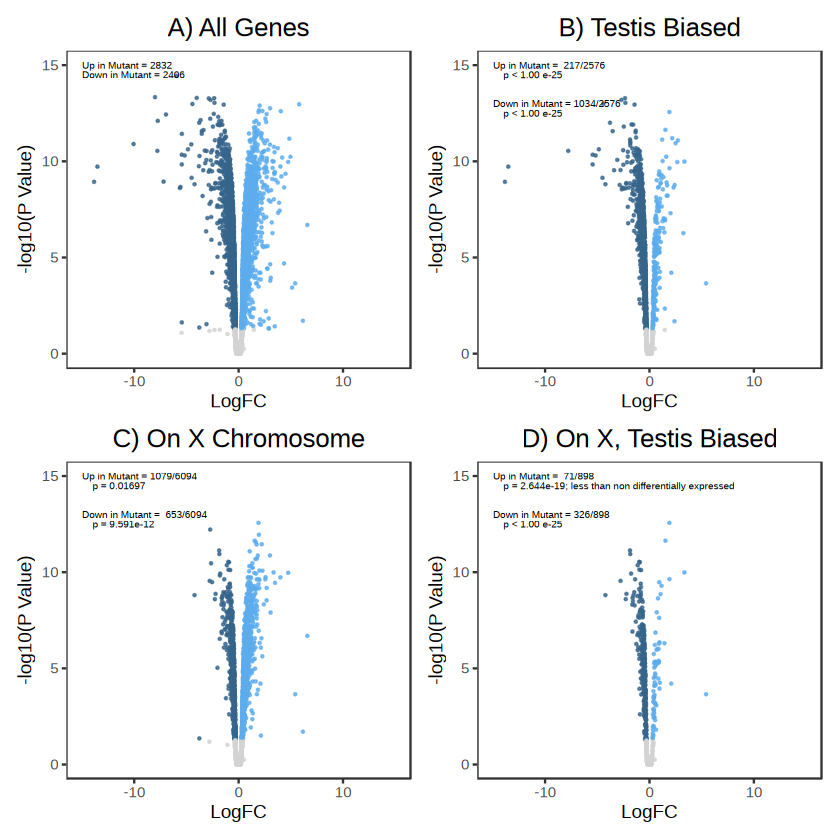

In [ ]:
## plot them together
figure4 <- (figure4a + figure4b) / (figure4c + figure4d)
figure4

In [ ]:
ggsave("figures/figure4.png", figure4, height = 6, width = 6)

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


### Figure 5

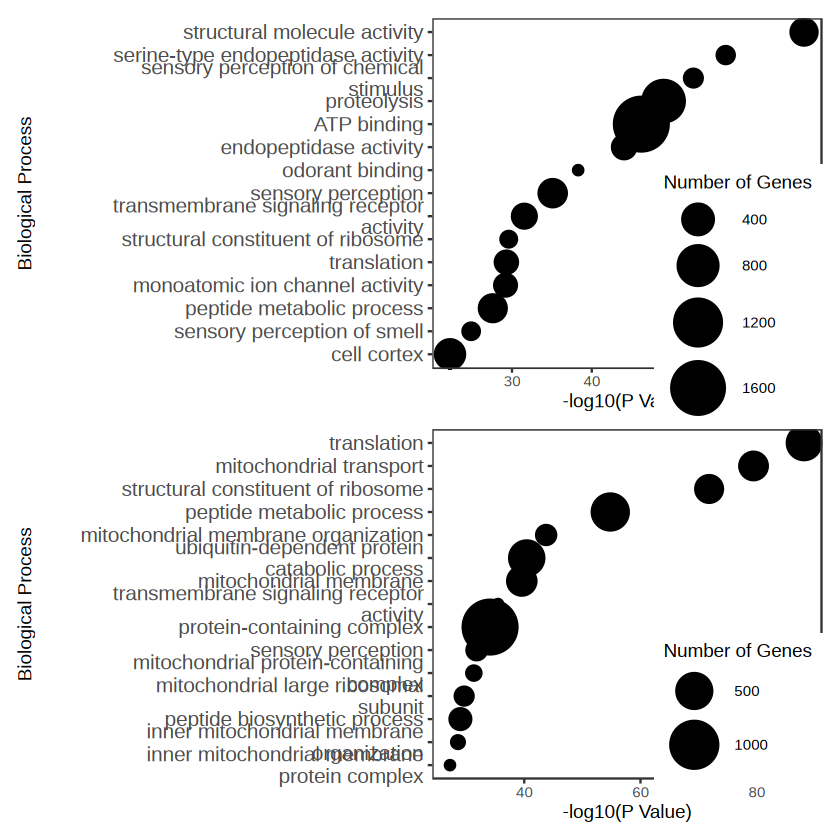

In [ ]:
## create list of cellular compartments
compartments <- c("mitochondrial inner membrane", "extracellular region", "mitochondrion", "plasma membrane", "ribosome", 
                 "extracellular space", "organelle inner membrane", "biological_process", "cellular_component", "ribosomal subunit", 
                 "molecular_function", "cytosol", "intracellular organelle")

## create dot plots
figure5a <- pseudoobscura_mutant_go %>%
    filter(!(go_term %in% compartments)) %>%
    filter(pvalue_corrected < 0.05 & direction == "up") %>%
    arrange(pvalue_corrected) %>%
    slice(1:15) %>%
    mutate(go_term = str_wrap(go_term, width = 35)) %>%
    ggplot(aes(x = fct_reorder(go_term, -log10(pvalue_corrected)), y = -log10(pvalue_corrected), size = go_genes)) +
        geom_point() +
        labs(x = "Biological Process", y = "-log10(P Value)", size = "Number of Genes") +
        # scale_color_gradient(low = "#C5E0B4", high = "#385723") +
        scale_size(range = c(2.5, 15)) +
        theme_bw() +
        theme(panel.grid = element_blank(),
              legend.position = c(0.8, 0.2),
              plot.title = element_text(size = 15),
              axis.text.y = element_text(size = 12)) +
        coord_flip()
figure5b <- pseudoobscura_mutant_go %>%
    filter(!(go_term %in% compartments)) %>%
    filter(pvalue_corrected < 0.05 & direction == "down") %>%
    arrange(pvalue_corrected) %>%
    slice(1:15) %>%
    mutate(go_term = str_wrap(go_term, width = 35)) %>%
    ggplot(aes(x = fct_reorder(go_term, -log10(pvalue_corrected)), y = -log10(pvalue_corrected), size = go_genes)) +
        geom_point() +
        labs(x = "Biological Process", y = "-log10(P Value)", size = "Number of Genes") +
        # scale_color_gradient(low = "#C5E0B4", high = "#385723") +
        scale_size(range = c(2.5, 15)) +
        theme_bw() +
        theme(panel.grid = element_blank(),
              legend.position = c(0.8, 0.2),
              plot.title = element_text(size = 15),
              axis.text.y = element_text(size = 12)) +
        coord_flip()
    
## plot together
figure5 <- figure5a / figure5b
figure5

In [ ]:
ggsave("figures/figure5.png", figure5, height = 13, width = 8)

### Figure 6

In [ ]:
## now look at credible, separating increase and decrease
credible_up <- annotated_logfc %>%
    filter(direction != "hypo") %>%
    group_by(credible, direction) %>%
    count() %>%
    pivot_wider(names_from = direction, values_from = n) %>%
    column_to_rownames("credible") %>%
    mutate_all(replace_na, replace = 0) %>%
    as.matrix() %>%
    chisq.test()
credible_up$p.value

credible_down <- annotated_logfc %>%
    filter(direction != "hyper") %>%
    group_by(credible, direction) %>%
    count() %>%
    pivot_wider(names_from = direction, values_from = n) %>%
    column_to_rownames("credible") %>%
    mutate_all(replace_na, replace = 0) %>%
    as.matrix() %>%
    chisq.test()
credible_down$p.value

[1] 2.014316e-08

[1] 6.846697e-47

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


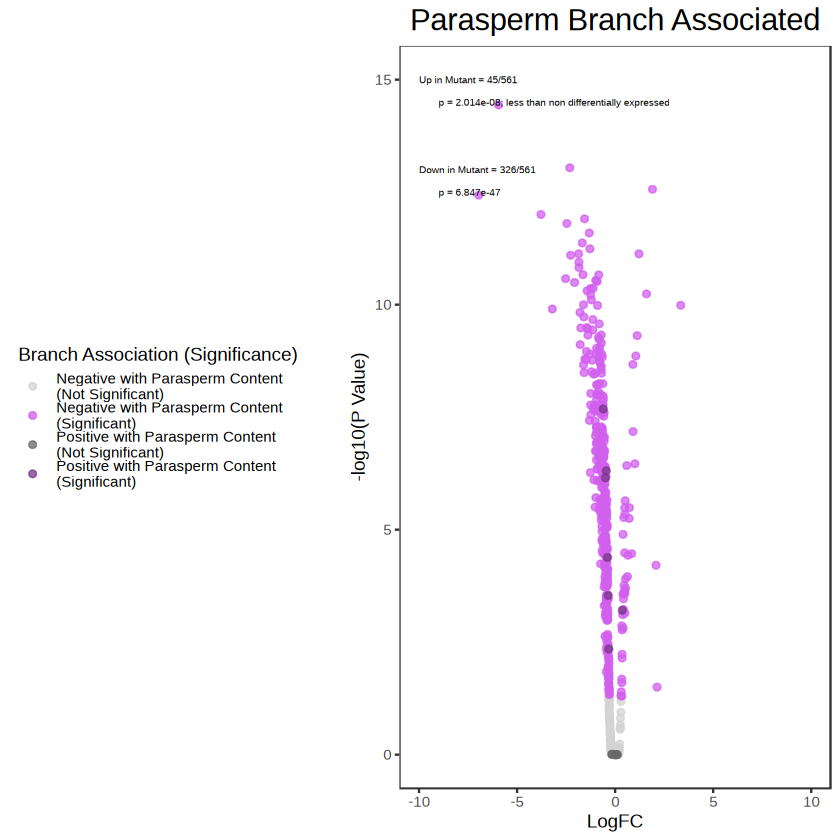

In [ ]:
## create graphs comparing deg and phylogenetic parasperm genes
logfc_credible <- annotated_logfc %>%
    mutate(association = case_when(gene %in% credible_down_genes & significance == "significant" ~ "Negative with Parasperm Content\n(Significant)",
                                   gene %in% credible_down_genes & significance == "not significant" ~ "Negative with Parasperm Content\n(Not Significant)",
                                   gene %in% credible_up_genes & significance == "significant" ~ "Positive with Parasperm Content\n(Significant)",
                                   gene %in% credible_up_genes & significance == "not significant" ~ "Positive with Parasperm Content\n(Not Significant)")) %>%
    na.omit() %>%
    arrange(factor(association, levels = c("Negative with Parasperm Content\n(Not Significant)", "Positive with Parasperm Content\n(Not Significant)", 
                                           "Negative with Parasperm Content\n(Significant)", "Positive with Parasperm Content\n(Significant)"))) %>%
    ggplot(aes(x = logfc, y = -log10(pvalue), color = association)) +
        geom_point(alpha = 0.75) +
        labs(title = "Parasperm Branch Associated", x = "LogFC", y = "-log10(P Value)", color = "Branch Association (Significance)") +
        xlim(-10, 10) +
        ylim(0, 15) +
        scale_color_manual(values = c("lightgray", "mediumorchid2", "dimgray", "mediumorchid4")) +
        theme_bw() +
        theme(panel.grid = element_blank(),
              legend.position = "left",
              plot.title = element_text(hjust = 0.5, size = 18))

## add graph details to credible
credible_numbers <- annotated_logfc %>%
    filter(credible == "credible") %>%
    count(direction) %>%
    column_to_rownames("direction")
up_crediblelabel <- paste0("Up in Mutant = ", credible_numbers["hyper", "n"], "/", length(credible_genes))
up_crediblep <- paste0("p = ", signif(credible_up$p.value, digits = 4), "; less than non differentially expressed")
down_crediblelabel <- paste0("Down in Mutant = ", credible_numbers["hypo", "n"], "/", length(credible_genes))
down_crediblep <- paste0("p = ", signif(credible_down$p.value, digits = 4))

figure6a <- logfc_credible +
    annotate("text", x = -10, y = 15, hjust = 0,
             size = 2, label = up_crediblelabel) +
    annotate("text", x = -9, y = 14.5, hjust = 0,
             size = 2, label = up_crediblep) +
    annotate("text", x = -10, y = 13, hjust = 0,
             size = 2, label = down_crediblelabel) +
    annotate("text", x = -9, y = 12.5, hjust = 0,
             size = 2, label = down_crediblep)
figure6a

In [ ]:
ggsave("figures/figure6a.png", figure6a, height = 4, width = 7)

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


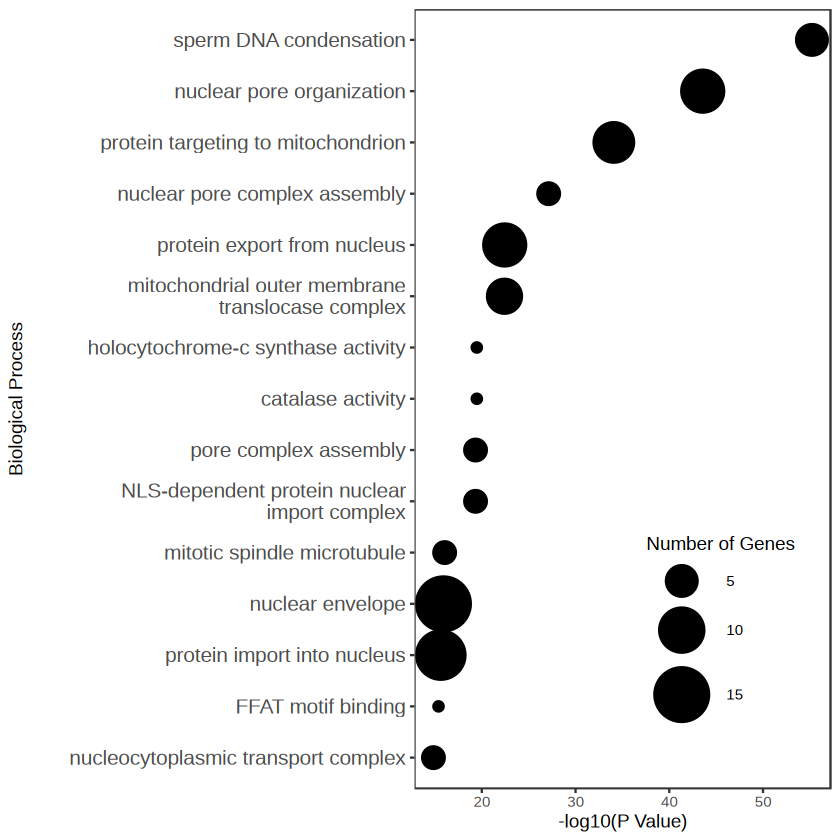

In [ ]:
## perform multiple testing correction 
downcred_go$pvalue_corrected <- p.adjust(downcred_go$go_pvalue, method = "BH")

## get the list of terms that are artifacts from Trinotate
## get list of terms that do not exist in Drosophila, as artifacts of Trinotate
artifacts <- c("T cells", "interferon")
artifacts <- paste(artifacts, collapse = "|")

## plot enriched GO terms
figure6b <- downcred_go %>%
    filter(pvalue_corrected < 0.05 & !grepl(artifacts, go_term)) %>%
    arrange(pvalue_corrected) %>%
    slice(1:15) %>%
    mutate(go_term = str_wrap(go_term, width = 35)) %>%
    ggplot(aes(x = fct_reorder(go_term, -log10(pvalue_corrected)), y = -log10(pvalue_corrected), size = go_genes)) +
        geom_point() +
        labs(x = "Biological Process", y = "-log10(P Value)", size = "Number of Genes") +
        # scale_color_gradient(low = "#C5E0B4", high = "#385723") +
        theme_bw() +
        scale_size(range = c(2.5, 15)) +
        theme(panel.grid = element_blank(),
              legend.position = c(0.75, 0.2),
              plot.title = element_text(size = 15),
              axis.text.y = element_text(size = 12)) +
        coord_flip()

figure6b

In [ ]:
ggsave("figures/figure6b.png", figure6b, height = 6, width = 7)

### Figure 7

In [ ]:
## get the list of genes with differential expression in the mutant
mutant_up_genes <- annotated_logfc %>%
    filter(direction == "hyper") %>%
    pull("gene")
mutant_down_genes <- annotated_logfc %>%
    filter(direction == "hypo") %>%
    pull("gene")

## annotated the single cell differentiation
figure7a <- logfc_morph %>%
    mutate(credible_up = case_when(gene %in% credible_up_genes ~ "credible_up",
                                   TRUE ~ "other"),
           credible_down = case_when(gene %in% credible_down_genes ~ "credible_down", 
                                     TRUE ~ "other"),
           mutant_up = case_when(gene %in% mutant_up_genes ~ "mutant_up",
                                 TRUE ~ "other"),
           mutant_down = case_when(gene %in% mutant_down_genes ~ "mutant_down", 
                                   TRUE ~ "other"),
           stage = case_when(stage == "early_spermatocyte" ~ "Early Spermatocyte",
                             stage == "late_spermatocyte" ~ "Late Spermatocyte")) %>%
    pivot_longer(c(credible_up, credible_down, mutant_up, mutant_down), names_to = "analysis", values_to = "value") %>%
    mutate(color = case_when(p_val_adj < 0.01 & avg_log2FC > 0 ~ "Up in Eusperm Cells",
                             p_val_adj < 0.01 & avg_log2FC < 0 ~ "Up in Parasperm Cells",
                             TRUE ~ "Not Significant"),
           color = fct_relevel(color, "Up in Eusperm Cells", "Up in Parasperm Cells", "Not Significant"), 
           analysis = case_when(analysis == "credible_down" ~ "Negatively Associated with\nParasperm Content",
                                analysis == "mutant_up" ~ "Upregulated in Mutant",
                                analysis == "mutant_down" ~ "Downregulated in Mutant"),
           analysis = fct_relevel(analysis, "Negatively Associated with\nParasperm Content", "Downregulated in Mutant", "Upregulated in Mutant")) %>%
    na.omit() %>%
    arrange(desc(color)) %>%
    filter(value != "other") %>%
    ggplot() +
        geom_point(aes(x = avg_log2FC, y = -log10(p_val_adj), color = color), alpha = 0.75, size = 0.75) +
        labs(title = "A", x = "logFC", y = "-log10(FDR)", color = "Sperm Morph Expression") +
        scale_color_manual(values = c("darkgreen", "darkolivegreen3", "lightgray")) +
        theme_bw() +
        theme(legend.position = "bottom") +
        facet_grid(cols = vars(analysis), rows = vars(stage))

In [ ]:
## get the list of genes of interest
mutant_genes <- variants %>%
    filter(consequence == "protein_altering_variant" | consequence == "stop_gained") %>%
    pull("symbol") %>% unique()

## filter single cell data for the mutant genes
morph_mutant <- FetchData(sce, vars = c(mutant_genes, "stage")) %>%
    rownames_to_column("cell") %>%
    pivot_longer(!c(cell, stage), names_to = "gene", values_to = "expression") %>%
    filter((grepl("C", stage) | grepl("S", stage))) %>%
    mutate(morph = case_when(grepl("Eu", stage) ~ "Eusperm",
                             grepl("Pa", stage) ~ "Parasperm"),
           comparison = case_when(grepl("Early", stage) ~ "early_spermatocyte",
                                  grepl("Late", stage) ~ "late_spermatocyte",
                                  grepl("S", stage) ~ "sperm"))

## add significance data to the single cell data
morph_mutant_annotated <- logfc_morph %>%
    select(gene, p_val_adj, stage) %>%
    filter(gene %in% mutant_genes) %>%
    rename(comparison = stage) %>%
    full_join(morph_mutant, by = c("comparison", "gene")) %>%
    mutate(significance = case_when(p_val_adj < 0.01 ~ 3.5))

## plot the expression of each gene for each stage comparison
figure7b <- morph_mutant_annotated %>%
    filter(comparison != "sperm") %>%
    mutate(comparison = case_when(comparison == "early_spermatocyte" ~ "Early Spermatocyte",
                                  comparison == "late_spermatocyte" ~ "Late Spermatocyte")) %>%
    ggplot() +
    geom_violin(aes(x = morph, y = expression, fill = morph)) +
    geom_point(aes(x = 1.5, y = significance), shape = 8) +
    labs(title = "B", y = "Expression Level", fill = "Sperm Morph") +
    scale_fill_manual(values = c("darkgreen", "darkolivegreen3")) +
    theme_bw() +
    theme(axis.title.x = element_blank(),
          axis.text.x = element_blank(),
          axis.ticks.x = element_blank(),
          legend.position = "bottom") +
    facet_grid(rows = vars(comparison), cols = vars(gene)) +
    theme(strip.text.x = element_text(size = 5))

Warning message:
“The following requested variables were not found: LOC4815774”


Warning message:
“Removed 88932 rows containing missing values or values outside the scale range
(`geom_point()`).”


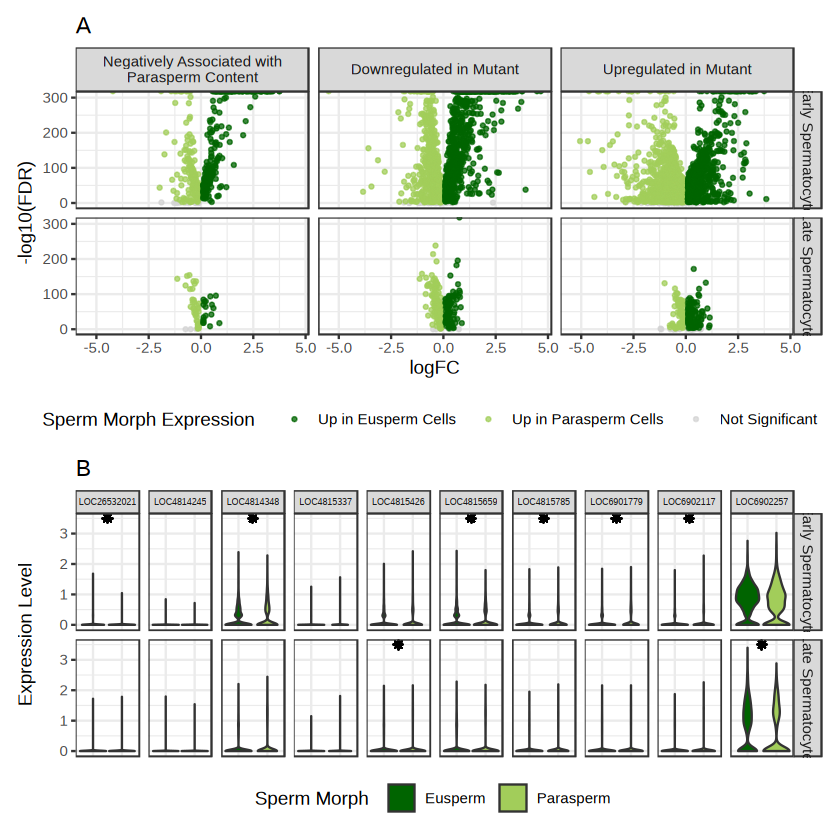

In [ ]:
## combine the separate portions of figure 7
figure7 <- figure7a/figure7b
figure7

In [ ]:
ggsave("figures/figure7.png", figure7, height = 10, width = 7)

Warning message:
“Removed 88932 rows containing missing values or values outside the scale range
(`geom_point()`).”


## Create Supplemental Figures

### Supplemental 1

Warning message:
“Cannot find identity NA”
Warning message:
“Cannot find identity NA”
Warning message:
“Cannot find identity NA”
Warning message:
“Cannot find identity NA”
Warning message:
“Cannot find identity NA”
Warning message:
“Cannot find identity NA”
Warning message:
“Cannot find identity NA”
Warning message:
“Cannot find identity NA”
Warning message:
“Cannot find identity NA”
Warning message:
“Cannot find identity NA”
Warning message:
“Cannot find identity NA”
Warning message:
“Cannot find identity NA”
Warning message:
“Cannot find identity NA”


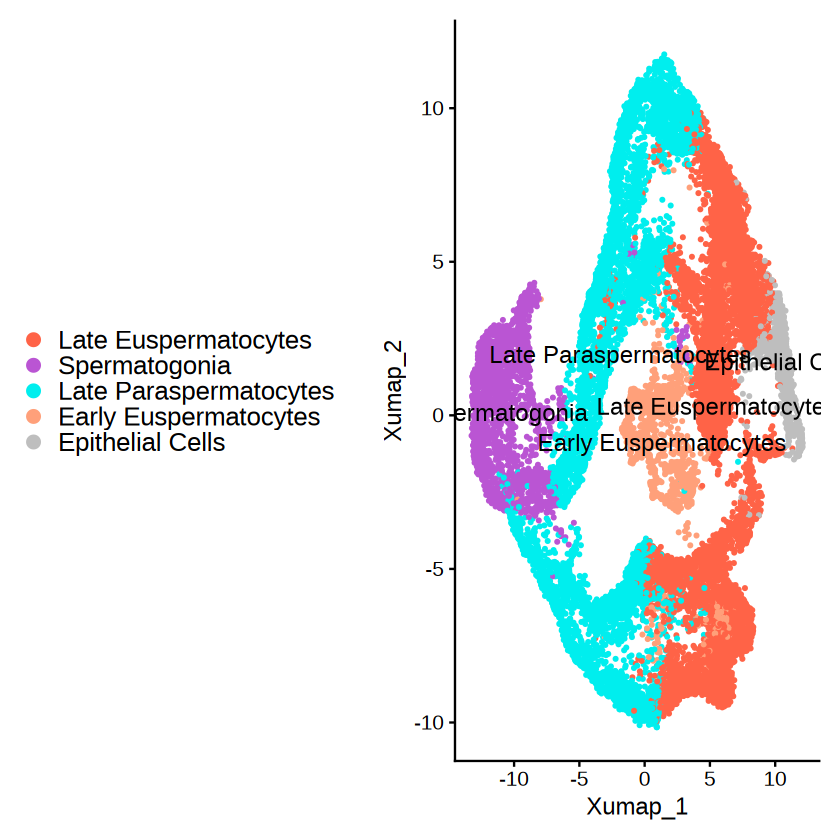

In [ ]:
## reannotated clusters based on cell type
cluster_names <- c("Late Euspermatocytes", "Spermatogonia", "Late Euspermatocytes", "Late Paraspermatocytes", "Early Euspermatocytes", 
                   "Late Paraspermatocytes", "Epithelial Cells", "Late Euspermatocytes", "Early Paraspermatocytes", "Early Euspermatocytes",
                   "Early Euspermatocytes", "Early Euspermatocytes", "Early Paraspermatocytes", "Spermatogonia", "Eusperm", "Early Paraspermatocytes", 
                   "Early Euspermatocytes", "Late Paraspermatocytes", "Parasperm", "Late Euspermatocytes", "Early Paraspermatocytes")
names(cluster_names) <- levels(sce)

## annotate the clusters
annotated_down_sce <- RenameIdents(sce, cluster_names)

## create colors for the clusters
cluster_colors <- c("Spermatogonia" = "mediumorchid",
                   "Early Euspermatocytes" = "lightsalmon", 
                   "Early Paraspermatocytes" = "darkslategray1",
                   "Late Euspermatocytes" = "tomato",
                   "Late Paraspermatocytes" = "cyan2",
                   "Eusperm" = "brown2",
                   "Parasperm" = "turquoise3",
                   "Epithelial Cells" = "gray")

## plot clusters, now with names
annotated_down_umap <- DimPlot(annotated_down_sce, reduction = "X_umap", cols = cluster_colors, label = TRUE, label.size = 5, pt.size = 0.5) +
    theme(legend.text = element_text(size = 15),
          legend.position = "left")
annotated_down_umap

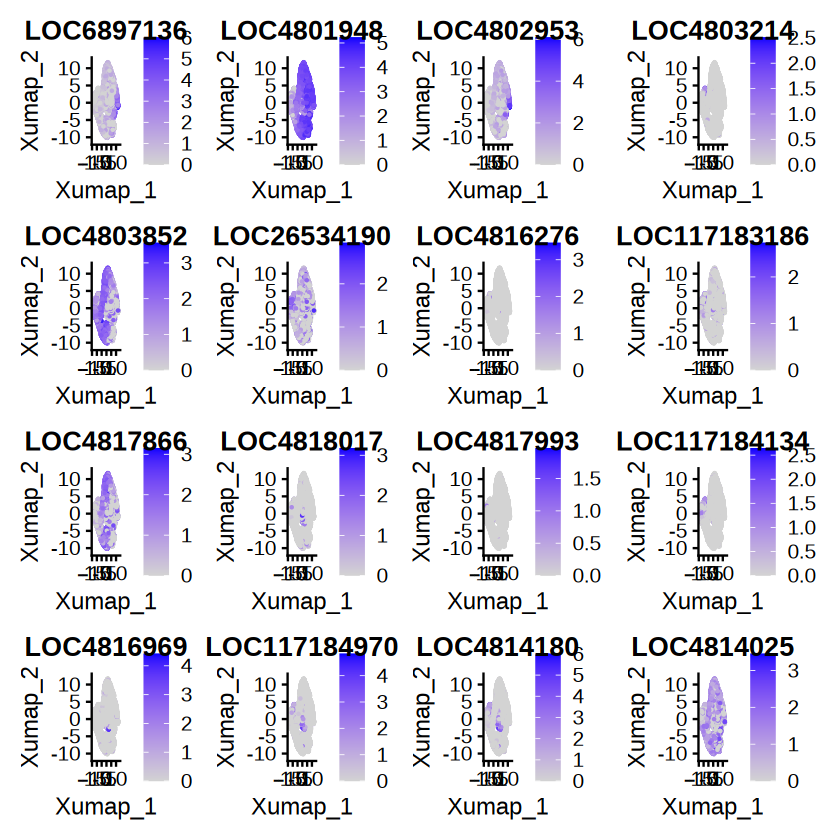

In [ ]:
## create data frame of genes from He et al. 2026
dmel_he_testis_genes <- data.frame(stage = c("GSC/Spermatogonia", "GSC/Spermatogonia", "GSC/Spermatogonia", "GSC/Spermatogonia", "GSC/Spermatogonia",
                                            "Early Spermatocytes", "Early Spermatocytes", "Early Spermatocytes",
                                            "Late Spermatocytes", "Late Spermatocytes", "Late Spermatocytes",
                                            "Spermatid", "Spermatid",
                                            "Cyst", "Cyst",
                                            "Hub", "Epithelial", "Epithelial"),
                                   dmel = c("AGO3", "aub", "bam", "vas", "aly", "can", "sa", "CycB", "twe", "bol", "soti", "wa-cup", "f-cup",
                                            "tj", "eya", "Fas3", "MtnA", "Hsp23"))

## get the D. miranda counterpart for each gene
he_testis_genes <- dmel_dpse %>%
    select(dmel, dpse) %>%
    right_join(dmel_he_testis_genes, by = "dmel")

markers_umap <- FeaturePlot(sce, features = na.omit(he_testis_genes$dpse))
markers_umap

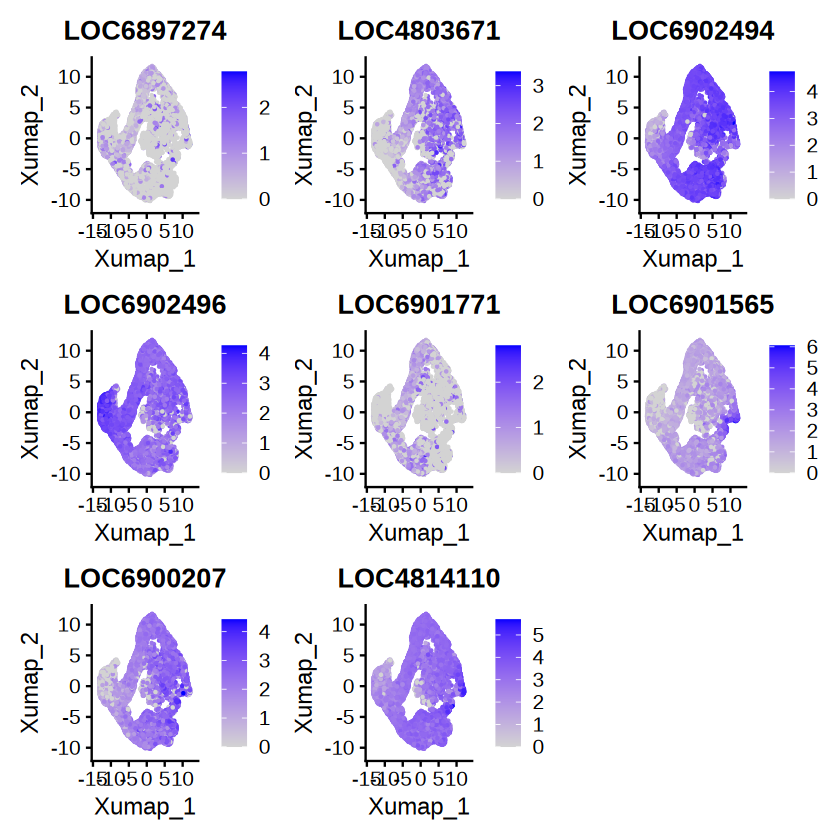

In [ ]:
## save the list of eusperm biased genes from He et al. 2026
eusperm_genes <- c("salto", "tbrd-1", "eIF4E3", "fan")

## get the pseudoobscura orthologs of these genes
eusperm_genes <- dmel_dpse %>%
    select(dmel, dpse) %>%
    filter(dmel %in% eusperm_genes)

## plot eusperm genes
eusperm_umap <- FeaturePlot(sce, features = eusperm_genes$dpse)
eusperm_umap

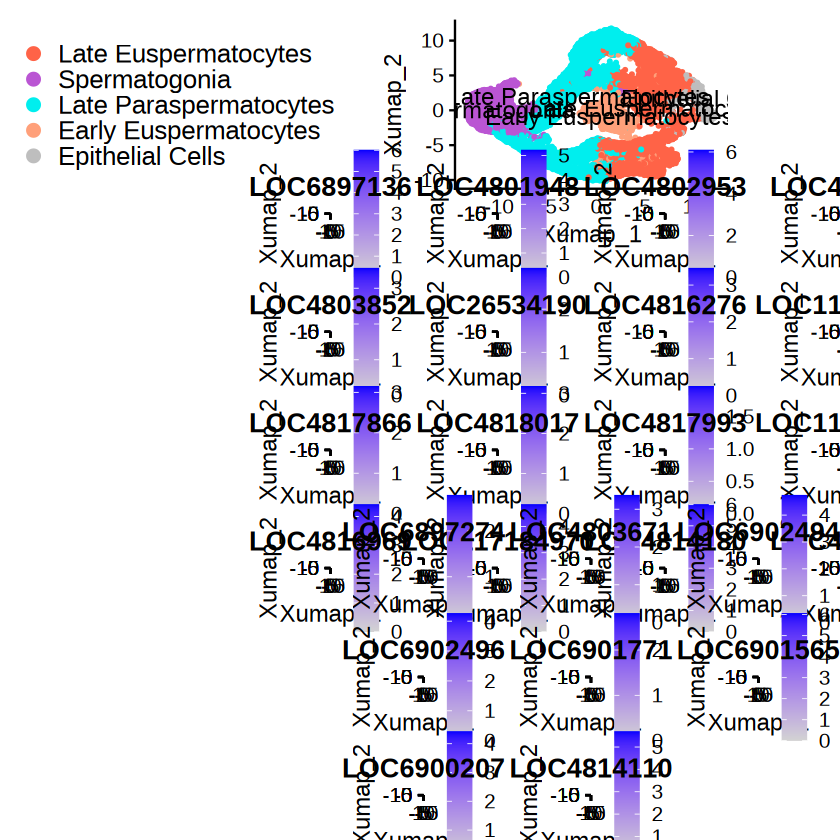

In [ ]:
supplemental1 <- annotated_down_umap / markers_umap / eusperm_umap
supplemental1

In [ ]:
ggsave("figures/supplemental1.png", supplemental1, height = 20, width = 14)

### Supplemental 2

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


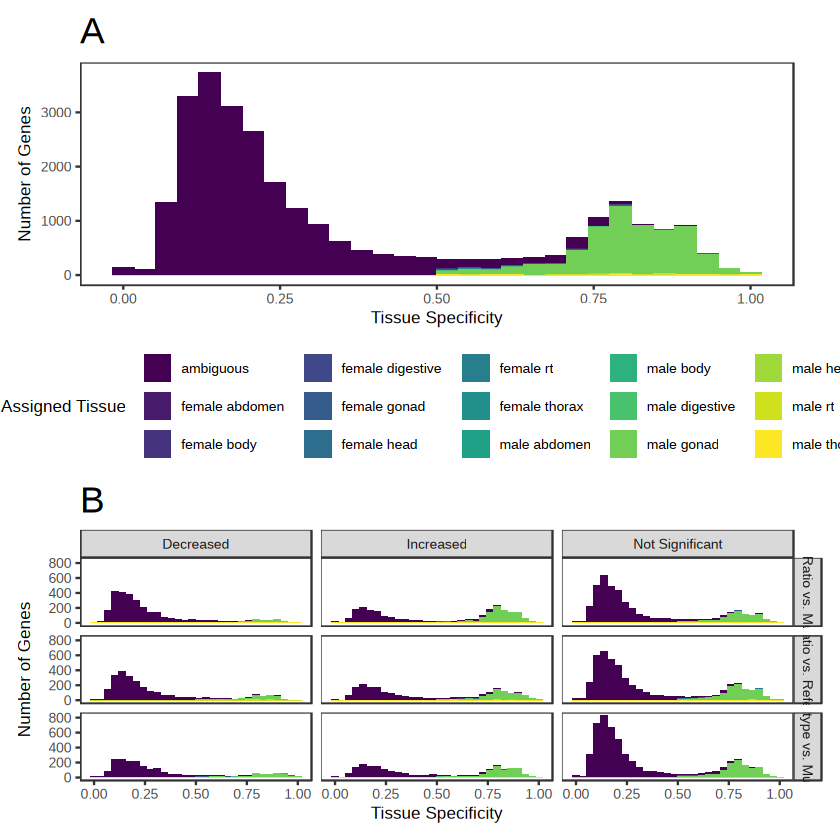

In [ ]:
## add tau information to comparison data
tau_comparison <- tau %>%
    full_join(logfc, by = "gene") %>%
    mutate(tau_tissue = str_replace_all(tau_tissue, "_", " "),
           direction = case_when(significance == "significant" & logfc > 0 ~ "Increased",
                                 significance == "significant" & logfc < 0 ~ "Decreased",
                                 TRUE ~ "Not Significant"),
           comparison = case_when(comparison == "reference_mutant" ~ "Wildtype vs. Mutant",
                                  comparison == "sex ratio_reference" ~ "Sex Ratio vs. Reference",
                                  comparison == "sex ratio_mutant" ~ "Sex Ratio vs. Mutant")) %>%
    na.omit()

## plot the distribution of tau based on the specific tissue and the comparison
supplemental2a <- tau_comparison %>%
    ggplot(aes(x = tau, fill = tau_tissue)) +
        geom_histogram() +
        scale_fill_viridis(discrete = TRUE) +
        labs(title = "A",
             x = "Tissue Specificity", y = "Number of Genes", fill = "Assigned Tissue") +
        theme_bw() +
        theme(panel.grid = element_blank(),
              legend.position = "bottom",
              text = element_text(size = 10),
              plot.title = element_text(size = 22))
supplemental2b <- tau_comparison %>%
    ggplot(aes(x = tau, fill = tau_tissue)) +
        geom_histogram() +
        scale_fill_viridis(discrete = TRUE) +
        labs(title = "B",
             x = "Tissue Specificity", y = "Number of Genes", fill = "Assigned Tissue") +
        theme_bw() +
        theme(panel.grid = element_blank(),
              legend.position = "none",
              text = element_text(size = 10),
              plot.title = element_text(size = 22)) +
        facet_grid(cols = vars(direction),
                   rows = vars(comparison))

## plot the two graphs together
supplemental2 <- supplemental2a / supplemental2b
supplemental2

In [ ]:
ggsave("figures/supplemental2.png", supplemental2, width = 10, height = 12, units = "in")

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


### Supplemental 3

Warning message:
“Removed 478 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 478 rows containing non-finite outside the scale range
(`stat_density()`).”


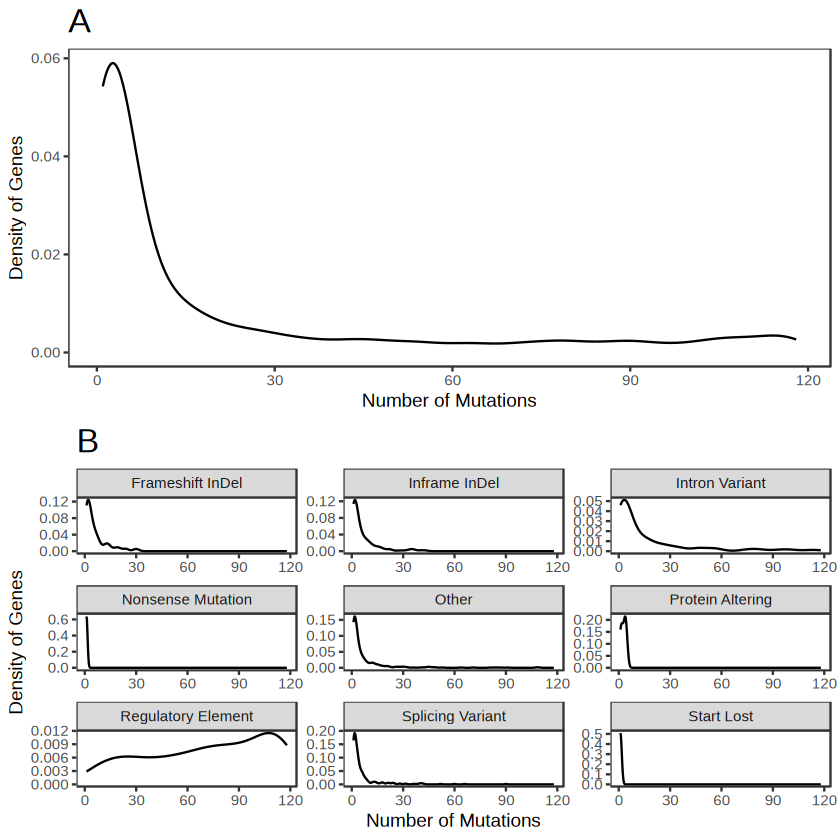

In [ ]:
## get the number of mutations per gene
regulator <- c("upstream_gene_variant", "downstream_gene_variant", "3_prime_UTR_variant", "5_prime_UTR_variant")

multi_mutations <- variants %>%
    separate_longer_delim(consequence, ",") %>%
    filter(biotype == "protein_coding" & consequence != "synonymous_variant") %>%
    mutate(mutation_type = case_when(consequence %in% regulator ~ "Regulatory Element",
                             consequence == "intron_variant" ~ "Intron Variant",
                             grepl("splice", consequence) ~ "Splicing Variant",
                             grepl("inframe", consequence) ~ "Inframe InDel",
                             grepl("frameshift", consequence) ~ "Frameshift InDel",
                             consequence == "protein_altering_variant" ~ "Protein Altering",
                             consequence == "stop_gained" ~ "Nonsense Mutation",
                             consequence == "start_lost" ~ "Start Lost",
                             TRUE ~ "Other")) %>%
    group_by(mutation_type, symbol) %>%
    reframe(count = n())

## find limit that 99% of genes are within
cap <- quantile(multi_mutations$count, probs = 0.75)
attributes(cap) <- NULL

multi_mutations_graph <- multi_mutations %>%
    ggplot(aes(x = count)) +
        geom_density() +
        labs(title = "A",
             x = "Number of Mutations", y = "Density of Genes") +
        xlim(1, cap) +
        theme_bw() +
        theme(panel.grid = element_blank(),
              plot.title = element_text(size = 20))
multi_mutations_type_graph <- multi_mutations %>%
    ggplot(aes(x = count)) +
        geom_density(alpha = 0.5) +
        labs(title = "B",
             x = "Number of Mutations", y = "Density of Genes") +
        # scale_color_viridis(discrete = TRUE) +
        # scale_fill_viridis(discrete = TRUE) +
        xlim(1, cap) +
        theme_bw() +
        theme(panel.grid = element_blank(),
              plot.title = element_text(size = 20)) + 
        facet_wrap(vars(mutation_type), scales = "free")
supplemental3 <- plot_grid(multi_mutations_graph, multi_mutations_type_graph, ncol = 1)
supplemental3

In [ ]:
ggsave("figures/supplemental3.png", supplemental3, height = 15, width = 10)

### Supplemental 4

Warning message:
“The following requested variables were not found: LOC6902416, LOC117185576, LOC4800918, LOC117183283”
Warning message:
“Removed 163103 rows containing missing values or values outside the scale range
(`geom_point()`).”


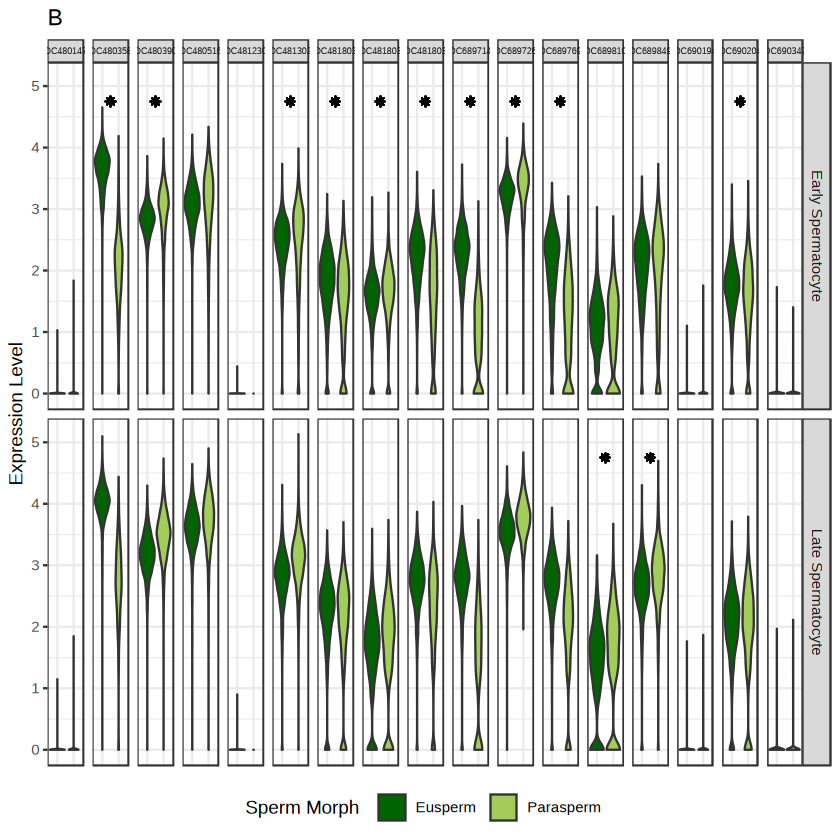

In [ ]:
## filter single cell data for the positive branch-associated genes
morph_mutant <- FetchData(sce, vars = c(credible_up_genes, "stage")) %>%
    rownames_to_column("cell") %>%
    pivot_longer(!c(cell, stage), names_to = "gene", values_to = "expression") %>%
    filter((grepl("C", stage) | grepl("S", stage))) %>%
    mutate(morph = case_when(grepl("Eu", stage) ~ "Eusperm",
                             grepl("Pa", stage) ~ "Parasperm"),
           comparison = case_when(grepl("Early", stage) ~ "early_spermatocyte",
                                  grepl("Late", stage) ~ "late_spermatocyte",
                                  grepl("S", stage) ~ "sperm"))

## add significance data to the single cell data
morph_positive_annotated <- logfc_morph %>%
    select(gene, p_val_adj, stage) %>%
    filter(gene %in% credible_up_genes) %>%
    rename(comparison = stage) %>%
    full_join(morph_mutant, by = c("comparison", "gene")) %>%
    mutate(significance = case_when(p_val_adj < 0.01 ~ 4.75))

## plot the expression of each gene for each stage comparison
supplemental4 <- morph_positive_annotated %>%
    filter(comparison != "sperm") %>%
    mutate(comparison = case_when(comparison == "early_spermatocyte" ~ "Early Spermatocyte",
                                  comparison == "late_spermatocyte" ~ "Late Spermatocyte")) %>%
    ggplot() +
    geom_violin(aes(x = morph, y = expression, fill = morph)) +
    geom_point(aes(x = 1.5, y = significance), shape = 8) +
    labs(y = "Expression Level", fill = "Sperm Morph") +
    scale_fill_manual(values = c("darkgreen", "darkolivegreen3")) +
    theme_bw() +
    theme(axis.title.x = element_blank(),
          axis.text.x = element_blank(),
          axis.ticks.x = element_blank(),
          legend.position = "bottom") +
    facet_grid(rows = vars(comparison), cols = vars(gene)) +
    theme(strip.text.x = element_text(size = 5))
supplemental4

In [ ]:
ggsave("figures/supplemental4.png", supplemental4, height = 5, width = 10)

Warning message:
“Removed 163103 rows containing missing values or values outside the scale range
(`geom_point()`).”
